In [12]:
# --- 1. SETUP & DEPENDENCIES ---
!pip install -q segmentation-models-pytorch rasterio albumentations

import os
import zipfile
import gc
from pathlib import Path
import torch

print("Initializing Kaggle Compute Node...")
gc.collect()
torch.cuda.empty_cache()

# --- 2. FORCE EXTRACTION & PATH RESOLUTION ---
KAGGLE_INPUT = Path("/kaggle/input")
WORKING_DIR = Path("/kaggle/working")
DATA_DIR = WORKING_DIR / "data"

# Check if uncompressed folders already exist in /kaggle/input
target_base_dir = next((Path(root) for root, dirs, _ in os.walk(KAGGLE_INPUT) if "PS-RGB" in dirs and "masks" in dirs), None)

if target_base_dir:
    print(f"[✓] Direct dataset found at: {target_base_dir}")
else:
    print("[!] Raw folders not found. Hunting for zip archive...")
    zip_candidates = list(KAGGLE_INPUT.glob("**/*.zip"))
    
    if not zip_candidates:
        raise FileNotFoundError(f"CRITICAL: No zip archive or PS-RGB folder found anywhere in {KAGGLE_INPUT}. Verify Kaggle Dataset upload.")
    
    zip_path = zip_candidates[0]
    print(f"[!] Extracting {zip_path.name} to {DATA_DIR}...")
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
    
    print("[✓] Extraction complete.")
    target_base_dir = next((Path(root) for root, dirs, _ in os.walk(DATA_DIR) if "PS-RGB" in dirs and "masks" in dirs), None)

if target_base_dir is None:
    raise FileNotFoundError("CRITICAL: Could not locate folders named 'PS-RGB' and 'masks' after extraction.")

IMAGE_DIR = target_base_dir / "PS-RGB"
MASK_DIR = target_base_dir / "masks"

# --- NESTED FOLDER FIX ---
# Detects and corrects Kaggle's double-nested upload behavior
if (IMAGE_DIR / "PS-RGB").is_dir():
    IMAGE_DIR = IMAGE_DIR / "PS-RGB"
    print(f"[!] Corrected double-nested image path: {IMAGE_DIR}")
    
if (MASK_DIR / "masks").is_dir():
    MASK_DIR = MASK_DIR / "masks"
    print(f"[!] Corrected double-nested mask path: {MASK_DIR}")

# Support multiple common formats case-insensitively
image_extensions = ("*.tif", "*.tiff", "*.png", "*.TIF", "*.TIFF", "*.PNG")
all_image_files = []
for ext in image_extensions:
    all_image_files.extend(list(IMAGE_DIR.glob(ext)))

all_image_files = sorted(list(set(all_image_files)))

print(f"\n[✓] Data locked and verified:")
print(f"    - Image Directory: {IMAGE_DIR}")
print(f"    - Mask Directory:  {MASK_DIR}")
print(f"    - Total Images Found: {len(all_image_files)}")

if len(all_image_files) == 0:
    raise ValueError(f"CRITICAL: 'PS-RGB' exists but contains no valid images. Contents: {os.listdir(IMAGE_DIR)[:10]}")

Initializing Kaggle Compute Node...
[✓] Direct dataset found at: /kaggle/input/datasets/ndsolanki/isro-dataset
[!] Corrected double-nested image path: /kaggle/input/datasets/ndsolanki/isro-dataset/PS-RGB/PS-RGB
[!] Corrected double-nested mask path: /kaggle/input/datasets/ndsolanki/isro-dataset/masks/masks

[✓] Data locked and verified:
    - Image Directory: /kaggle/input/datasets/ndsolanki/isro-dataset/PS-RGB/PS-RGB
    - Mask Directory:  /kaggle/input/datasets/ndsolanki/isro-dataset/masks/masks
    - Total Images Found: 1016


In [14]:
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import segmentation_models_pytorch as smp
import rasterio
import numpy as np
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

# --- 1. DATASET DEFINITION ---
class SpaceNetDataset(Dataset):
    def __init__(self, file_list, mask_dir, phase="train"):
        self.image_files = file_list
        self.mask_dir = Path(mask_dir)
        self.phase = phase

        if self.phase == "train":
            self.transform = A.Compose([
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5),
                A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
                ToTensorV2()
            ])
        else:
            self.transform = A.Compose([ToTensorV2()])

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        img_path = self.image_files[idx]
        mask_path = self.mask_dir / img_path.name.replace("PS-RGB_", "mask_")

        with rasterio.open(img_path) as src:
            image = np.moveaxis(src.read(), 0, -1)
            image = (image / 255.0).astype(np.float32)

        with rasterio.open(mask_path) as src:
            mask = (src.read(1) > 0).astype(np.float32)

        if self.transform:
            augmented = self.transform(image=image, mask=mask)
            image = augmented['image']
            mask = augmented['mask'].unsqueeze(0)

        return image, mask

# --- 2. DATALOADERS & HARDWARE ---
train_files, val_files = train_test_split(all_image_files, test_size=0.2, random_state=42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == 'cpu': 
    raise SystemError("GPU NOT DETECTED. Turn on GPU T4 x2 in Notebook Settings -> Accelerator.")

BATCH_SIZE = 4
train_loader = DataLoader(SpaceNetDataset(train_files, MASK_DIR, phase="train"), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
val_loader = DataLoader(SpaceNetDataset(val_files, MASK_DIR, phase="val"), batch_size=BATCH_SIZE, shuffle=False)

# --- 3. MODEL ARCHITECTURE & LOSS ---
model = smp.Unet(encoder_name="resnet18", encoder_weights="imagenet", in_channels=3, classes=1).to(device)
bce_loss = nn.BCEWithLogitsLoss()
dice_loss = smp.losses.DiceLoss(mode='binary', from_logits=True)

def composite_loss(outputs, masks):
    return bce_loss(outputs, masks) + dice_loss(outputs, masks)

def calculate_iou(preds, labels, threshold=0.5):
    preds = torch.sigmoid(preds)
    preds = (preds > threshold).float()
    intersection = (preds * labels).sum()
    union = preds.sum() + labels.sum() - intersection
    if union == 0: return torch.tensor(1.0)
    return intersection / union

optimizer = optim.Adam(model.parameters(), lr=1e-3)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=3)

# --- 4. CHECKPOINT LOGIC (KAGGLE WORKING DIR) ---
CHECKPOINT_DIR = Path("/kaggle/working/checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_PATH = CHECKPOINT_DIR / "unet_best_model.pth"

best_val_loss = float('inf')
EPOCHS = 30
from tqdm import tqdm

# --- 5. TRAINING LOOP (WITH LIVE TELEMETRY) ---
print(f"Starting Production Training on {device.type.upper()}...")
for epoch in range(EPOCHS):
    model.train()
    train_loss, train_iou = 0.0, 0.0

    # Live progress bar for Training
    train_pbar = tqdm(train_loader, desc=f"Epoch [{epoch+1:02d}/{EPOCHS}] Train")
    for images, masks in train_pbar:
        images, masks = images.to(device), masks.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = composite_loss(outputs, masks)
        loss.backward()
        optimizer.step()

        batch_loss = loss.item()
        batch_iou = calculate_iou(outputs, masks).item()
        
        train_loss += batch_loss
        train_iou += batch_iou
        
        # Update progress bar with live metrics
        train_pbar.set_postfix(loss=f"{batch_loss:.4f}", iou=f"{batch_iou:.4f}")

    model.eval()
    val_loss, val_iou = 0.0, 0.0
    
    # Live progress bar for Validation
    val_pbar = tqdm(val_loader, desc=f"Epoch [{epoch+1:02d}/{EPOCHS}] Val  ")
    with torch.no_grad():
        for images, masks in val_pbar:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            
            batch_loss = composite_loss(outputs, masks).item()
            batch_iou = calculate_iou(outputs, masks).item()
            
            val_loss += batch_loss
            val_iou += batch_iou

    avg_train_loss = train_loss / len(train_loader)
    avg_val_loss = val_loss / len(val_loader)
    avg_val_iou = val_iou / len(val_loader)
    
    scheduler.step(avg_val_loss)

    print(f"\n=> Epoch {epoch+1} Summary | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val IoU: {avg_val_iou:.4f}")

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'best_val_loss': best_val_loss,
        }, CHECKPOINT_PATH)
        print("   [+] Validation improved! Weights saved to /kaggle/working.")
    print("-" * 70)

Starting Production Training on CUDA...


Epoch [01/30] Val  : 100%|██████████| 51/51 [00:43<00:00,  1.16it/s]



=> Epoch 1 Summary | Train Loss: 0.8418 | Val Loss: 0.7357 | Val IoU: 0.3631
   [+] Validation improved! Weights saved to /kaggle/working.
----------------------------------------------------------------------


Epoch [02/30] Val  : 100%|██████████| 51/51 [00:28<00:00,  1.81it/s]



=> Epoch 2 Summary | Train Loss: 0.6999 | Val Loss: 0.6886 | Val IoU: 0.4025
   [+] Validation improved! Weights saved to /kaggle/working.
----------------------------------------------------------------------


Epoch [03/30] Val  : 100%|██████████| 51/51 [00:29<00:00,  1.75it/s]


... (49 outputs left out)

Epoch [29/30] Val  : 100%|██████████| 51/51 [00:28<00:00,  1.81it/s]



=> Epoch 29 Summary | Train Loss: 0.4554 | Val Loss: 0.4889 | Val IoU: 0.5501
----------------------------------------------------------------------


Epoch [30/30] Val  : 100%|██████████| 51/51 [00:27<00:00,  1.86it/s]



=> Epoch 30 Summary | Train Loss: 0.4243 | Val Loss: 0.4611 | Val IoU: 0.5696
   [+] Validation improved! Weights saved to /kaggle/working.
----------------------------------------------------------------------


--- EXECUTING TOPOLOGICAL TRANSLATION ---


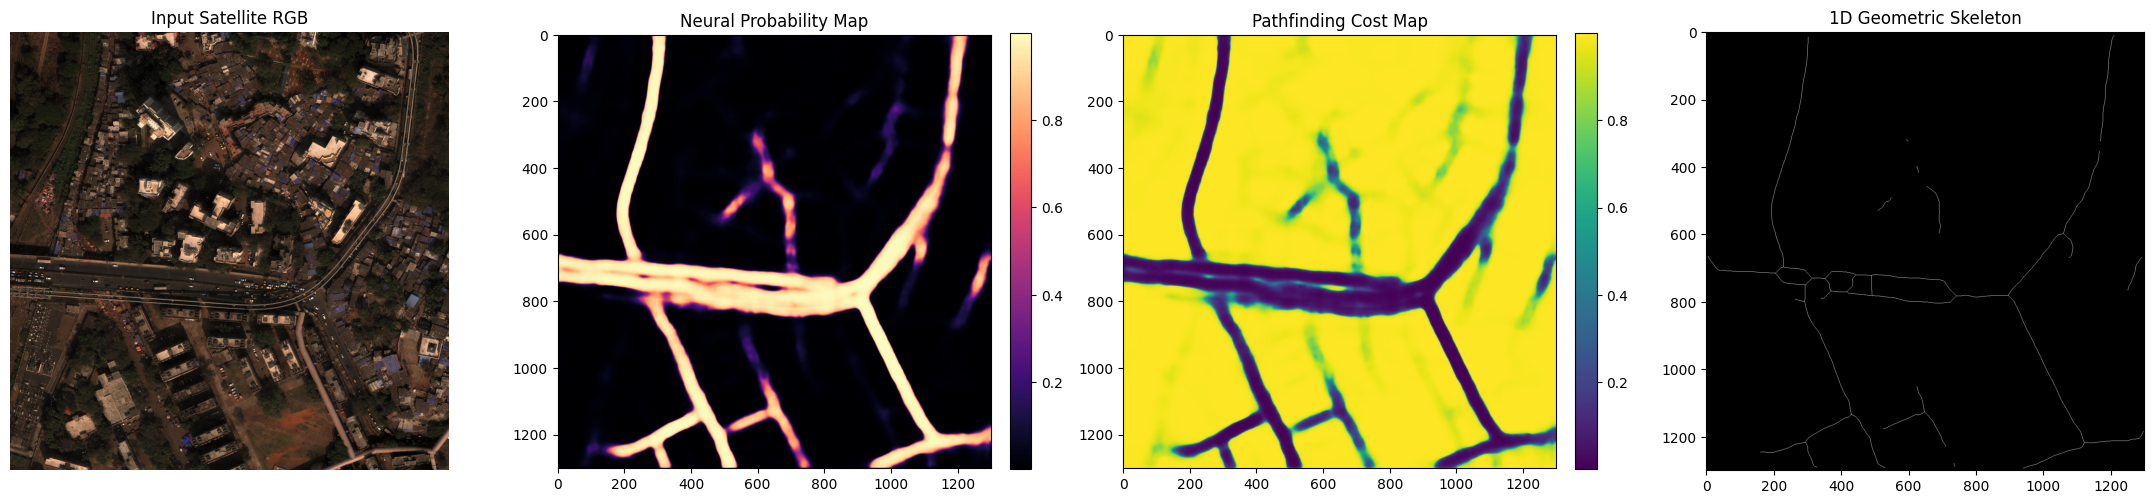

[✓] Arrays exported to /kaggle/working/artifacts. Available for download in the Kaggle Output panel.


In [15]:
import matplotlib.pyplot as plt
from skimage.morphology import skeletonize

print("--- EXECUTING TOPOLOGICAL TRANSLATION ---")

# Load best weights
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

# Grab a single sample from validation
images, masks = next(iter(val_loader))

with torch.no_grad():
    raw_logits = model(images.to(device))
    prob_map = torch.sigmoid(raw_logits)[0].squeeze().cpu().numpy()

# Mathematical Inversion for Routing Friction
cost_map = 1.0 - prob_map

# Strict thresholding to prevent geometric spurs
binary_confident = prob_map > 0.65
skeleton = skeletonize(binary_confident)

# --- RENDERING ---
fig, ax = plt.subplots(1, 4, figsize=(22, 5))

ax[0].imshow(images[0].permute(1, 2, 0).numpy())
ax[0].set_title("Input Satellite RGB")
ax[0].axis('off')

im1 = ax[1].imshow(prob_map, cmap='magma')
ax[1].set_title("Neural Probability Map")
fig.colorbar(im1, ax=ax[1], fraction=0.046, pad=0.04)

im2 = ax[2].imshow(cost_map, cmap='viridis')
ax[2].set_title("Pathfinding Cost Map")
fig.colorbar(im2, ax=ax[2], fraction=0.046, pad=0.04)

ax[3].imshow(skeleton, cmap='gray')
ax[3].set_title("1D Geometric Skeleton")

plt.tight_layout()
plt.show()

# --- EXPORT ARTIFACTS ---
SAVE_DIR = Path("/kaggle/working/artifacts")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

np.save(SAVE_DIR / "cost_map.npy", cost_map)
np.save(SAVE_DIR / "skeleton.npy", skeleton)
print(f"[✓] Arrays exported to {SAVE_DIR}. Available for download in the Kaggle Output panel.")